In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

import folium
from folium.plugins import HeatMap, MarkerCluster

import warnings
import time
import joblib
import os

warnings.filterwarnings("ignore")

# Machine Learning
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

# Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

print("All libraries imported successfully.")

All libraries imported successfully.


# load dataset

In [2]:
file_path = "Crime_Data_from_2020_to_Present.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (1005198, 28)


In [3]:
df.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,190326475,03-01-2020 00:00,03-01-2020 00:00,2130,7,Wilshire,784,1,510,VEHICLE - STOLEN,...,AA,Adult Arrest,510.0,998.0,NaN,NaN,1900 S LONGWOOD AV,NaN,34.0375,-118.3506
1,200106753,02-09-2020 00:00,02-08-2020 00:00,1800,1,Central,182,1,330,BURGLARY FROM VEHICLE,...,IC,Invest Cont,330.0,998.0,NaN,NaN,1000 S FLOWER ST,NaN,34.0444,-118.2628
2,200320258,11-11-2020 00:00,11-04-2020 00:00,1700,3,Southwest,356,1,480,BIKE - STOLEN,...,IC,Invest Cont,480.0,NaN,NaN,NaN,1400 W 37TH ST,NaN,34.0210,-118.3002
3,200907217,05-10-2023 00:00,03-10-2020 00:00,2037,9,Van Nuys,964,1,343,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),...,IC,Invest Cont,343.0,NaN,NaN,NaN,14000 RIVERSIDE DR,NaN,34.1576,-118.4387
4,200412582,09-09-2020 00:00,09-09-2020 00:00,630,4,Hollenbeck,413,1,510,VEHICLE - STOLEN,...,IC,Invest Cont,510.0,NaN,NaN,NaN,200 E AVENUE 28,NaN,34.0820,-118.2130


In [4]:
df.tail()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
1005193,250304214,2/23/2025 0:00,2/21/2025 0:00,1530,3,Southwest,358,1,510,VEHICLE - STOLEN,...,IC,Invest Cont,510.0,NaN,NaN,NaN,3600 MCCLINTOCK AV,NaN,34.0212,-118.2895
1005194,250304203,2/20/2025 0:00,2/13/2025 0:00,2100,3,Southwest,325,1,522,"VEHICLE, STOLEN - OTHER (MOTORIZED SCOOTERS, B...",...,IC,Invest Cont,522.0,NaN,NaN,NaN,2600 ELLENDALE PL,NaN,34.0307,-118.2923
1005195,250504051,1/14/2025 0:00,1/14/2025 0:00,1250,5,Harbor,509,1,210,ROBBERY,...,IC,Invest Cont,210.0,NaN,NaN,NaN,24300 WESTERN AV,NaN,33.8046,-118.3074
1005196,251604136,2/27/2025 0:00,2/27/2025 0:00,1550,16,Foothill,1664,1,510,VEHICLE - STOLEN,...,AA,Adult Arrest,510.0,NaN,NaN,NaN,11900 SHELDON ST,NaN,34.2404,-118.3922
1005197,251904210,3/25/2025 0:00,3/25/2025 0:00,1235,19,Mission,1944,2,850,INDECENT EXPOSURE,...,IC,Invest Cont,850.0,NaN,NaN,NaN,11100 OMELVENY AV,NaN,34.2722,-118.4417


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1005198
Columns: 28


# inspect dataset 

In [6]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME', 'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes', 'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc', 'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1', 'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT', 'LON']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005198 entries, 0 to 1005197
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1005198 non-null  int64  
 1   Date Rptd       1005198 non-null  object 
 2   DATE OCC        1005198 non-null  object 
 3   TIME OCC        1005198 non-null  int64  
 4   AREA            1005198 non-null  int64  
 5   AREA NAME       1005198 non-null  object 
 6   Rpt Dist No     1005198 non-null  int64  
 7   Part 1-2        1005198 non-null  int64  
 8   Crm Cd          1005198 non-null  int64  
 9   Crm Cd Desc     1005198 non-null  object 
 10  Mocodes         853438 non-null   object 
 11  Vict Age        1005198 non-null  int64  
 12  Vict Sex        860416 non-null   object 
 13  Vict Descent    860404 non-null   object 
 14  Premis Cd       1005182 non-null  float64
 15  Premis Desc     1004610 non-null  object 
 16  Weapon Used Cd  327280 non-null   fl

In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
DR_NO,1005198.0,NaN,NaN,NaN,220227677.865526,13202822.081133,817.0,210616927.25,220916044.0,231110516.25,252104146.0
Date Rptd,1005198,1906,02-02-2023 00:00,929,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DATE OCC,1005198,1901,01-01-2020 00:00,1164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TIME OCC,1005198.0,NaN,NaN,NaN,1339.911378,651.053143,1.0,900.0,1420.0,1900.0,2359.0
AREA,1005198.0,NaN,NaN,NaN,10.690975,6.110385,1.0,5.0,11.0,16.0,21.0
AREA NAME,1005198,21,Central,69674,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rpt Dist No,1005198.0,NaN,NaN,NaN,1115.556245,611.173335,101.0,587.0,1139.0,1613.0,2199.0
Part 1-2,1005198.0,NaN,NaN,NaN,1.400283,0.489956,1.0,1.0,1.0,2.0,2.0
Crm Cd,1005198.0,NaN,NaN,NaN,500.145783,205.263461,110.0,331.0,442.0,626.0,956.0
Crm Cd Desc,1005198,140,VEHICLE - STOLEN,115247,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# PART 4 — Missing Value Analysis

In [9]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    "Missing_Percentage",
    ascending=False
)

missing

,Missing_Count,Missing_Percentage
Crm Cd 4,1005134,99.993633
Crm Cd 3,1002884,99.769797
Crm Cd 2,936039,93.119863
Cross Street,850955,84.655461
Weapon Used Cd,677918,67.441240
Weapon Desc,677918,67.441240
Mocodes,151760,15.097523
Vict Descent,144794,14.404525
Vict Sex,144782,14.403331
Premis Desc,588,0.058496


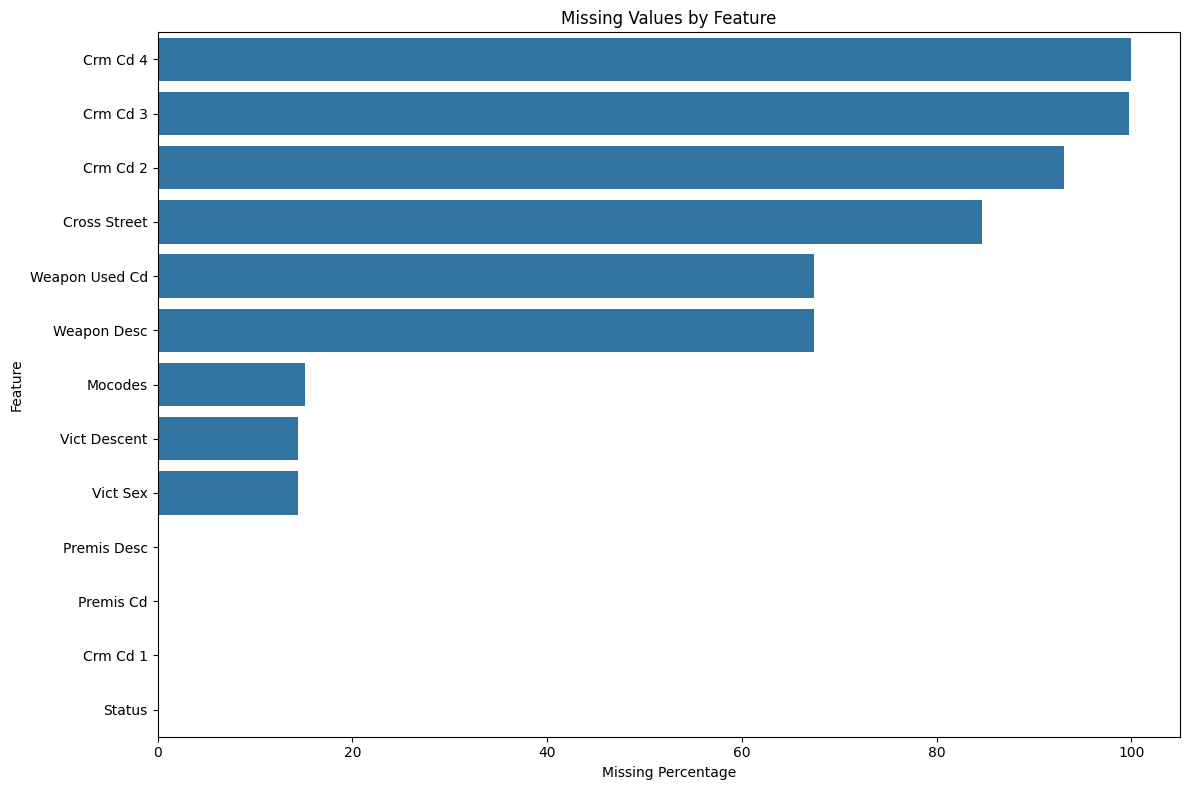

In [10]:
plt.figure(figsize=(12, 8))

missing_nonzero = missing[
    missing["Missing_Count"] > 0
]

sns.barplot(
    x=missing_nonzero["Missing_Percentage"],
    y=missing_nonzero.index
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing Percentage")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

# PART 5 — Duplicate Detection

In [11]:
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


# PART 6 — Date Processing

In [12]:
df["Date Rptd"] = pd.to_datetime(
    df["Date Rptd"],
    errors="coerce"
)

df["DATE OCC"] = pd.to_datetime(
    df["DATE OCC"],
    errors="coerce"
)

# PART 7 — Feature Engineering

In [13]:
df["Year"] = df["DATE OCC"].dt.year

In [14]:
df["Month"] = df["DATE OCC"].dt.month

In [15]:
df["Day"] = df["DATE OCC"].dt.day

In [16]:
df["DayOfWeek"] = df["DATE OCC"].dt.dayofweek

In [17]:
df["DayName"] = df["DATE OCC"].dt.day_name()

# PART 8 — Process TIME OCC

In [18]:
df["TIME OCC"] = pd.to_numeric(
    df["TIME OCC"],
    errors="coerce"
)

df["Hour"] = (df["TIME OCC"] // 100)

df["Hour"] = pd.to_numeric(
    df["Hour"],
    errors="coerce"
)

df.loc[
    ~df["Hour"].between(0, 23),
    "Hour"
] = np.nan

df["Hour"].value_counts().sort_index()

Hour
0.0     40481
1.0     29764
2.0     25217
3.0     22193
4.0     18758
5.0     17292
6.0     23187
7.0     26270
8.0     37257
9.0     36534
10.0    43029
11.0    43670
12.0    67836
13.0    45593
14.0    49324
15.0    52839
16.0    52987
17.0    58827
18.0    59966
19.0    55616
20.0    56358
21.0    50800
22.0    49117
23.0    42283
Name: count, dtype: int64

# PART 9 — Weekend Feature

In [19]:
df["IsWeekend"] = (
    df["DayOfWeek"] >= 5
).astype(int)

df["IsWeekend"].value_counts()

IsWeekend
0    886195
1    119003
Name: count, dtype: int64

# PART 10 — Time of Day

In [20]:
def get_time_of_day(hour):

    if pd.isna(hour):
        return "Unknown"

    elif 5 <= hour < 12:
        return "Morning"

    elif 12 <= hour < 17:
        return "Afternoon"

    elif 17 <= hour < 21:
        return "Evening"

    else:
        return "Night"

In [21]:
df["TimeOfDay"] = df["Hour"].apply(
    get_time_of_day
)

In [22]:
df["TimeOfDay"].value_counts()

TimeOfDay
Night        278613
Afternoon    268579
Evening      230767
Morning      227239
Name: count, dtype: int64

# PART 11 — Season

In [23]:
def get_season(month):

    if pd.isna(month):
        return "Unknown"

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Spring"

    elif month in [6, 7, 8]:
        return "Summer"

    else:
        return "Autumn"

df["Season"] = df["Month"].apply(
    get_season
)

# PART 12 — Victim Age Cleaning

In [24]:
df["Vict Age"] = pd.to_numeric(
    df["Vict Age"],
    errors="coerce"
)
df.loc[
    (df["Vict Age"] <= 0) |
    (df["Vict Age"] > 100),
    "Vict Age"
] = np.nan

# PART 13 — Latitude and Longitude Cleaning

In [25]:
df["LAT"] = pd.to_numeric(
    df["LAT"],
    errors="coerce"
)

df["LON"] = pd.to_numeric(
    df["LON"],
    errors="coerce"
)

# PART 14 — Check the Dataset Again

In [26]:
print("Final dataset shape:", df.shape)

Final dataset shape: (1005198, 37)


In [27]:
df.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,LON,Year,Month,Day,DayOfWeek,DayName,Hour,IsWeekend,TimeOfDay,Season
0,190326475,2020-03-01,2020-03-01,2130,7,Wilshire,784,1,510,VEHICLE - STOLEN,...,-118.3506,2020.0,3.0,1.0,6.0,Sunday,21.0,1,Night,Spring
1,200106753,2020-02-09,2020-02-08,1800,1,Central,182,1,330,BURGLARY FROM VEHICLE,...,-118.2628,2020.0,2.0,8.0,5.0,Saturday,18.0,1,Evening,Winter
2,200320258,2020-11-11,2020-11-04,1700,3,Southwest,356,1,480,BIKE - STOLEN,...,-118.3002,2020.0,11.0,4.0,2.0,Wednesday,17.0,0,Evening,Autumn
3,200907217,2023-05-10,2020-03-10,2037,9,Van Nuys,964,1,343,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),...,-118.4387,2020.0,3.0,10.0,1.0,Tuesday,20.0,0,Evening,Spring
4,200412582,2020-09-09,2020-09-09,630,4,Hollenbeck,413,1,510,VEHICLE - STOLEN,...,-118.2130,2020.0,9.0,9.0,2.0,Wednesday,6.0,0,Morning,Autumn


# MODULE 1 — EDA

# PART 15 — Crime Class Distribution

In [28]:
df["Part 1-2"].value_counts()

Part 1-2
1    602834
2    402364
Name: count, dtype: int64

In [29]:
df["Part 1-2"].value_counts(
    normalize=True
) * 100

Part 1-2
1    59.971667
2    40.028333
Name: proportion, dtype: float64

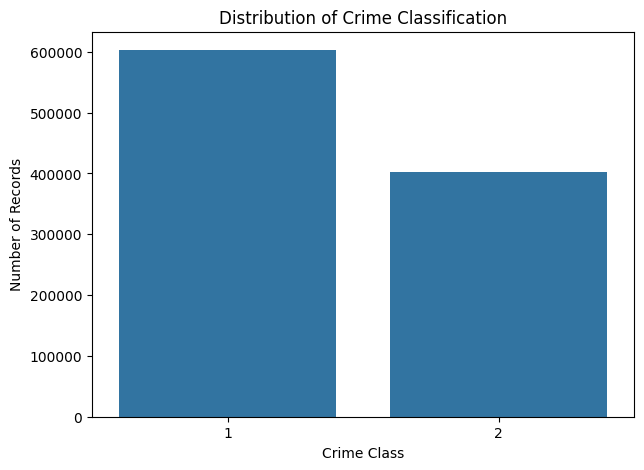

In [30]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Part 1-2"
)

plt.title("Distribution of Crime Classification")
plt.xlabel("Crime Class")
plt.ylabel("Number of Records")

plt.show()

# PART 16 — Crime Trend by Year

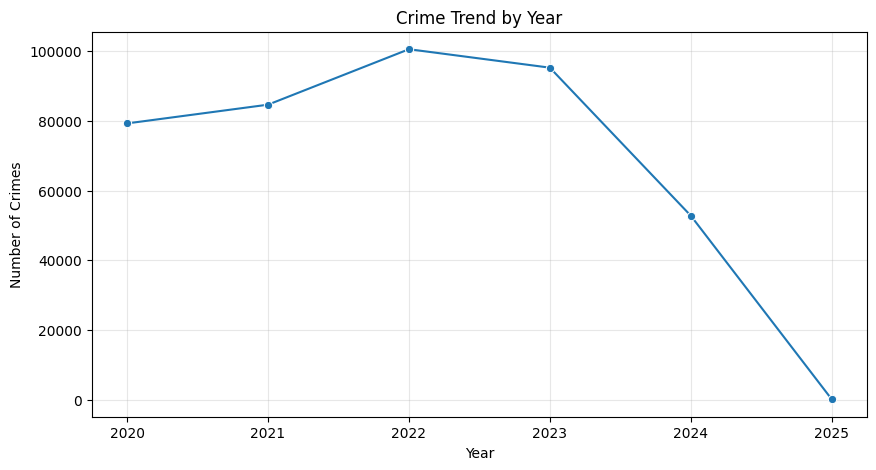

In [31]:
year_counts = (
    df["Year"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=year_counts.index,
    y=year_counts.values,
    marker="o"
)

plt.title("Crime Trend by Year")
plt.xlabel("Year")
plt.ylabel("Number of Crimes")

plt.grid(alpha=0.3)
plt.show()

# PART 17 — Crime by Month

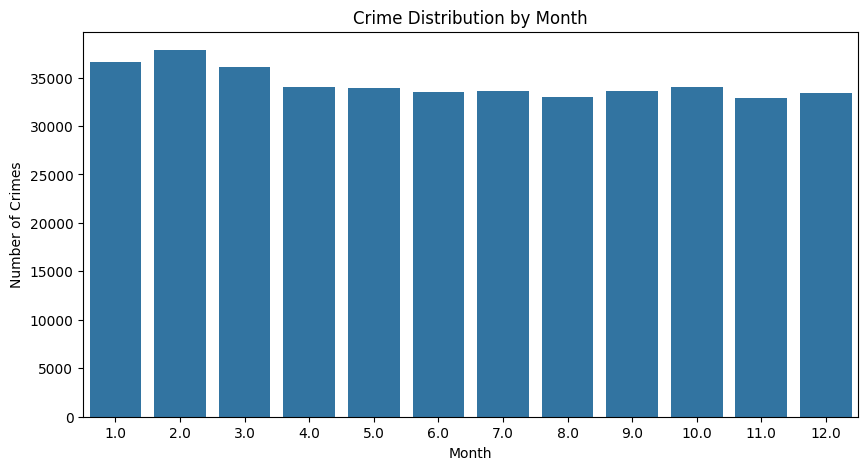

In [32]:
month_counts = (
    df["Month"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_counts.index,
    y=month_counts.values
)

plt.title("Crime Distribution by Month")
plt.xlabel("Month")
plt.ylabel("Number of Crimes")

plt.show()

# PART 18 — Crime by Hour

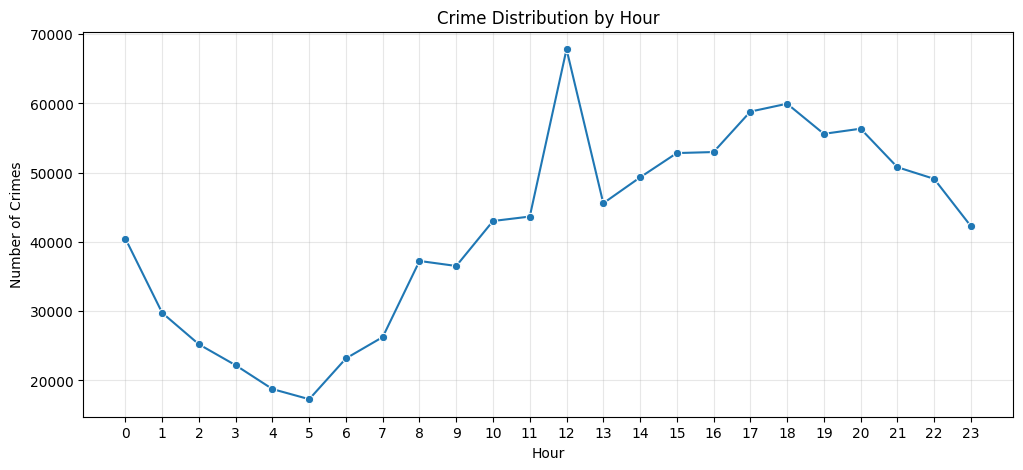

In [33]:
hour_counts = (
    df["Hour"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hour_counts.index,
    y=hour_counts.values,
    marker="o"
)

plt.xticks(range(24))

plt.title("Crime Distribution by Hour")
plt.xlabel("Hour")
plt.ylabel("Number of Crimes")

plt.grid(alpha=0.3)
plt.show()


# PART 19 — Crime by Day

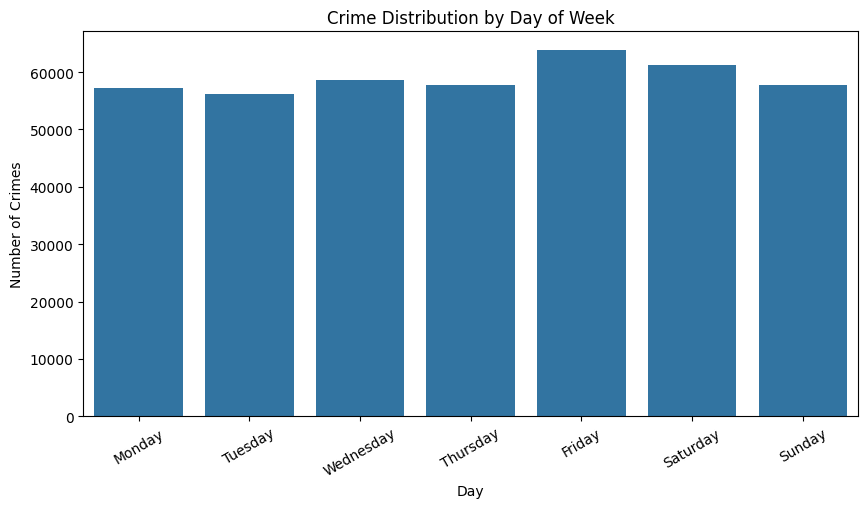

In [34]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="DayName",
    order=day_order
)

plt.title("Crime Distribution by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Crimes")

plt.xticks(rotation=30)

plt.show()

# PART 20 — Crime by Area

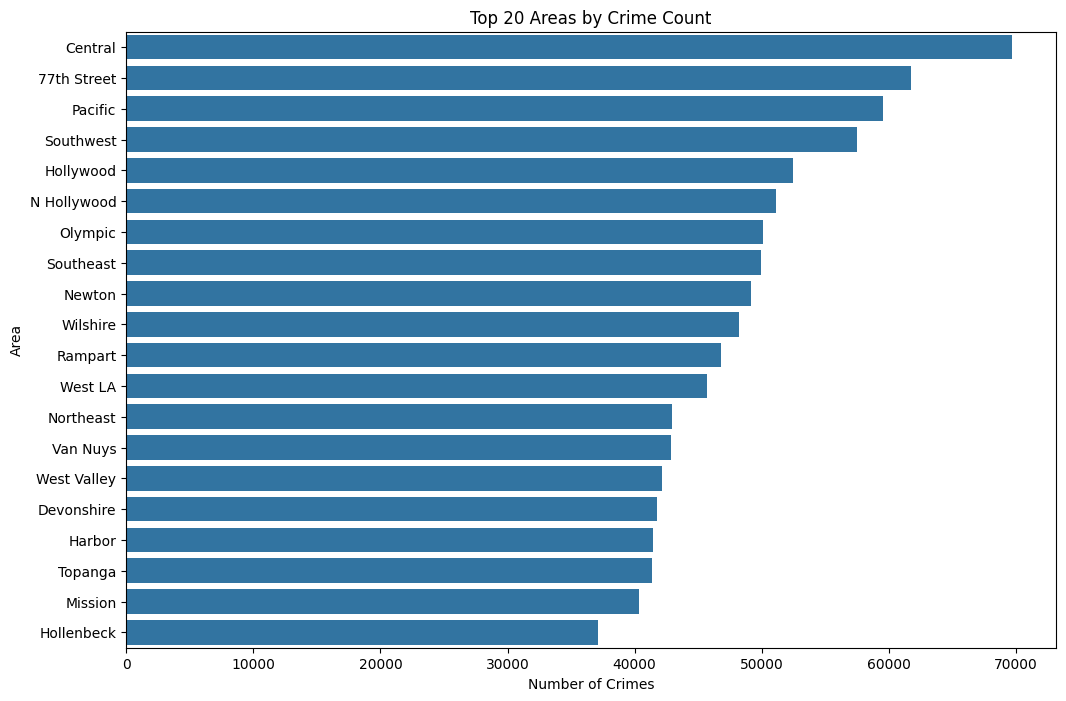

In [35]:
area_counts = (
    df["AREA NAME"]
    .value_counts()
    .head(20)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=area_counts.values,
    y=area_counts.index
)

plt.title("Top 20 Areas by Crime Count")
plt.xlabel("Number of Crimes")
plt.ylabel("Area")

plt.show()

# PART 21 — Top Crime Types

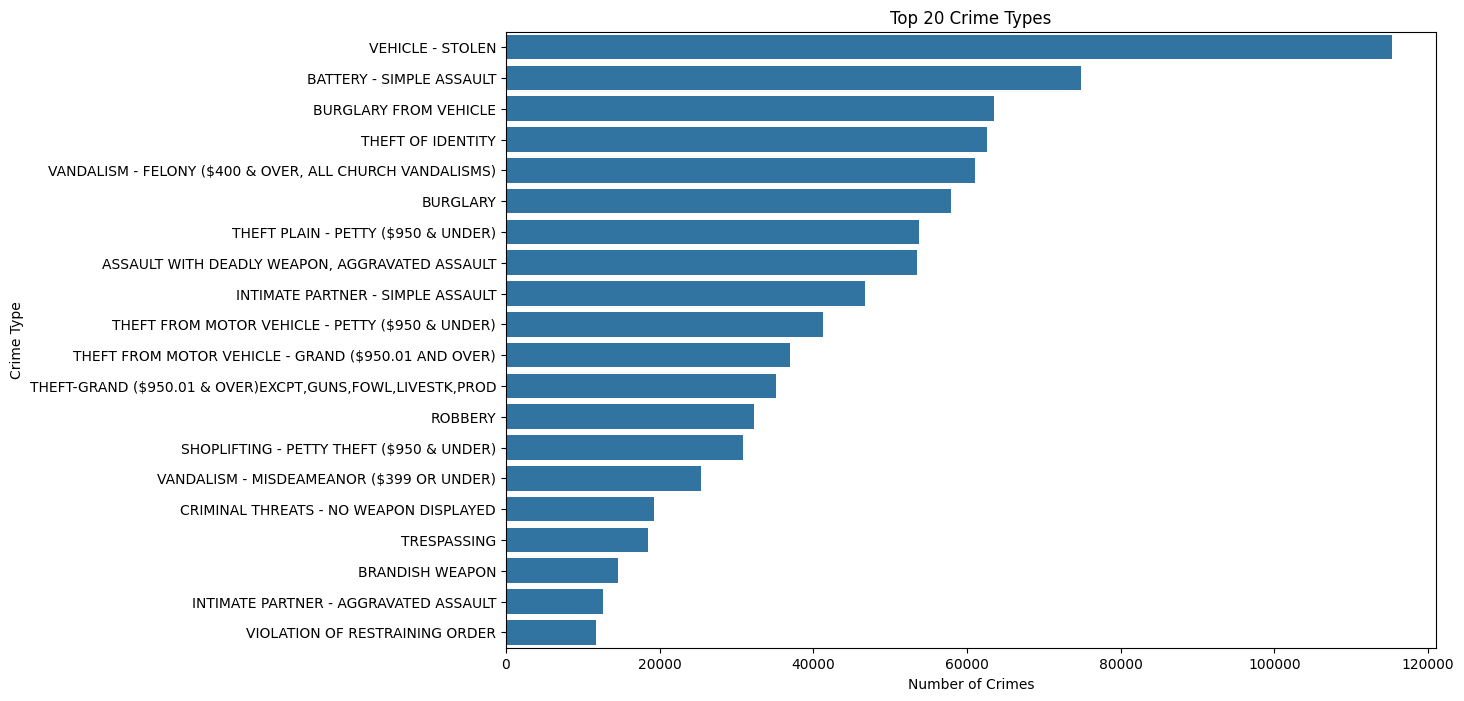

In [36]:
crime_counts = (
    df["Crm Cd Desc"]
    .value_counts()
    .head(20)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=crime_counts.values,
    y=crime_counts.index
)

plt.title("Top 20 Crime Types")
plt.xlabel("Number of Crimes")
plt.ylabel("Crime Type")

plt.show()

# PART 22 — Victim Age Distribution

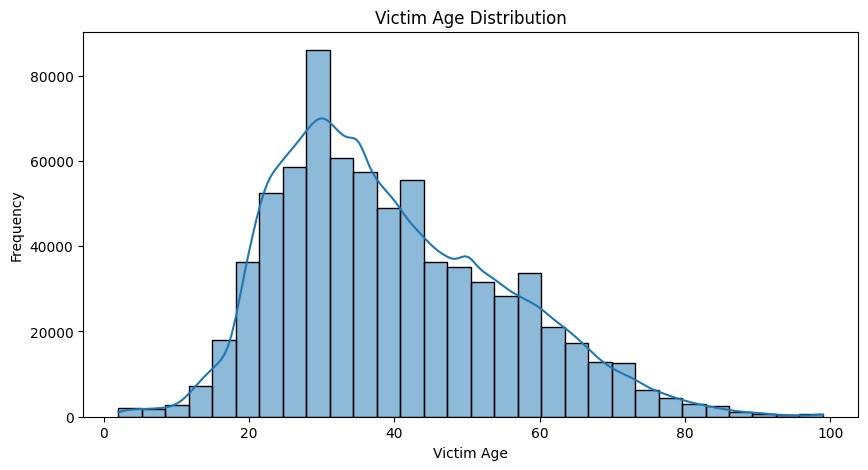

In [37]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Vict Age"].dropna(),
    bins=30,
    kde=True
)

plt.title("Victim Age Distribution")
plt.xlabel("Victim Age")
plt.ylabel("Frequency")

plt.show()

# PART 23 — Crime Class vs Time of Day

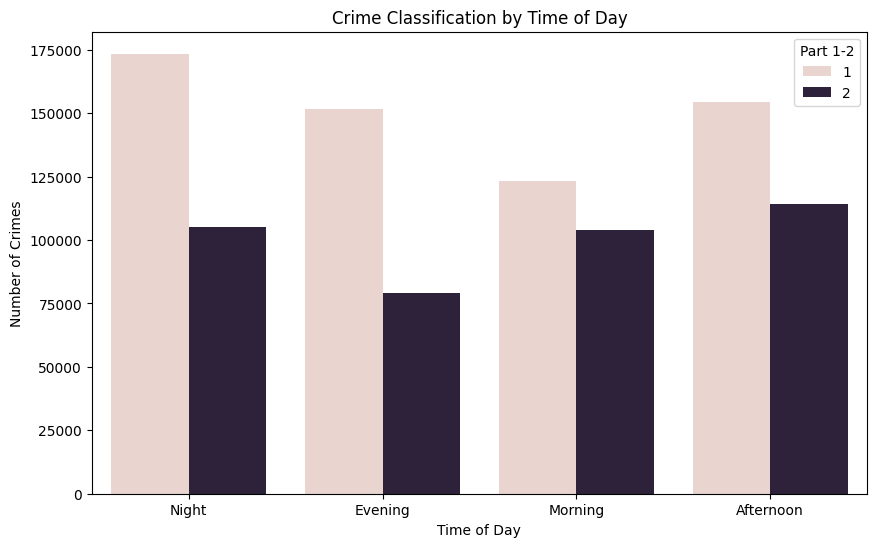

In [38]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="TimeOfDay",
    hue="Part 1-2"
)

plt.title("Crime Classification by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Number of Crimes")

plt.show()

# PART 24 — Crime Class by Area

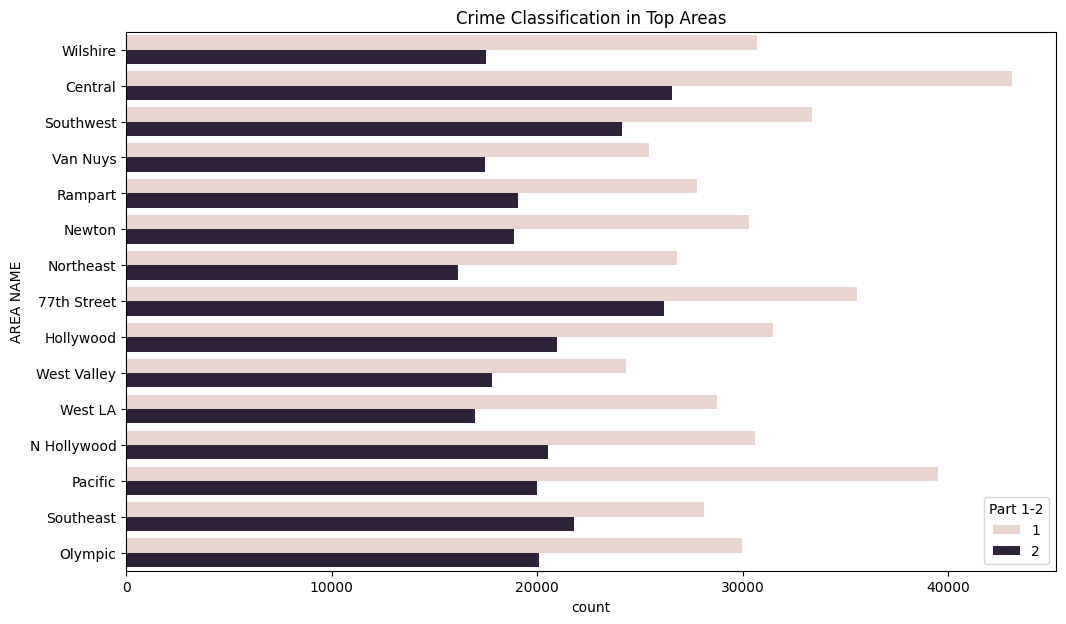

In [39]:
area_class = pd.crosstab(
    df["AREA NAME"],
    df["Part 1-2"]
)

area_class.head()

top_areas = (
    df["AREA NAME"]
    .value_counts()
    .head(15)
    .index
)

temp = df[
    df["AREA NAME"].isin(top_areas)
]

plt.figure(figsize=(12, 7))

sns.countplot(
    data=temp,
    y="AREA NAME",
    hue="Part 1-2"
)

plt.title("Crime Classification in Top Areas")

plt.show()


# MODULE 2 — CRIME CLASSIFICATION

# PART 25 — Select ML Features

**Methodology correction:** split the data before feature selection; use only the training partition for feature selection and cross-validation; use the held-out test set once for final evaluation. `Part 1-2` is treated as a Part I vs Part II crime classification target, not a general crime-severity score.


In [40]:
# PART 25 — Prepare the classification dataset

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import time

target = "Part 1-2"
candidate_features = [
    "AREA NAME", "Vict Age", "Vict Sex", "Vict Descent",
    "Premis Desc", "Weapon Desc", "Hour", "Month",
    "DayOfWeek", "TimeOfDay"
]
required = candidate_features + [target]
missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Required columns missing from df: {missing}. Run the feature-engineering cells first.")

model_df = df[required].copy()
model_df[target] = pd.to_numeric(model_df[target], errors="coerce")
model_df = model_df[model_df[target].isin([1, 2])].copy()
model_df[target] = model_df[target].map({1: 0, 2: 1}).astype(int)

# Treat implausible victim ages as missing rather than as real ages.
model_df["Vict Age"] = pd.to_numeric(model_df["Vict Age"], errors="coerce")
model_df.loc[~model_df["Vict Age"].between(0, 110), "Vict Age"] = np.nan
for col in ["Hour", "Month", "DayOfWeek"]:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

# Keep a reproducible, stratified sample for reasonable notebook runtime.
MAX_ROWS = 300_000
if len(model_df) > MAX_ROWS:
    model_df, _ = train_test_split(
        model_df, train_size=MAX_ROWS, stratify=model_df[target], random_state=42
    )
model_df = model_df.reset_index(drop=True)

X = model_df[candidate_features].copy()
y = model_df[target].copy()
X_train_full, X_test_final, y_train_full, y_test_final = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
print("Rows used:", len(model_df))
print("Training rows:", len(X_train_full), "| Held-out test rows:", len(X_test_final))
print("Target mapping: Part I (1) -> 0; Part II (2) -> 1")
print("Training target distribution:\n", y_train_full.value_counts(normalize=True).sort_index())


Rows used: 300000
Training rows: 240000 | Held-out test rows: 60000
Target mapping: Part I (1) -> 0; Part II (2) -> 1
Training target distribution:
 Part 1-2
0    0.599717
1    0.400283
Name: proportion, dtype: float64


In [41]:
# PART 26 — Feature selection using training data only

numeric_features_fs = ["Vict Age", "Hour", "Month", "DayOfWeek"]
categorical_features_fs = [
    "AREA NAME", "Vict Sex", "Vict Descent", "Premis Desc", "Weapon Desc", "TimeOfDay"
]

fs_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features_fs),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features_fs)
    ],
    remainder="drop"
)

X_fit, X_fs_valid, y_fit, y_fs_valid = train_test_split(
    X_train_full, y_train_full, test_size=0.20, stratify=y_train_full, random_state=42
)
fs_pipeline = Pipeline([
    ("preprocessor", fs_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=150, min_samples_leaf=2, class_weight="balanced",
        n_jobs=-1, random_state=42
    ))
])
fs_pipeline.fit(X_fit, y_fit)
perm = permutation_importance(
    fs_pipeline, X_fs_valid, y_fs_valid, scoring="f1",
    n_repeats=5, random_state=42, n_jobs=1
)
permutation_results = pd.DataFrame({
    "Feature": candidate_features,
    "Importance Mean": perm.importances_mean,
    "Importance Std": perm.importances_std
}).sort_values("Importance Mean", ascending=False).reset_index(drop=True)
permutation_results["Lower Bound"] = (
    permutation_results["Importance Mean"] - 2 * permutation_results["Importance Std"]
)
display(permutation_results)

selected_features = permutation_results.loc[
    permutation_results["Lower Bound"] > 0, "Feature"
].tolist()
# Defensive fallback: do not allow an empty feature set if all noisy estimates cross zero.
if not selected_features:
    selected_features = permutation_results.head(5)["Feature"].tolist()
print("Selected features:", selected_features)
print("Note: permutation importance is a model-dependent ranking, not proof of causality.")


,Feature,Importance Mean,Importance Std,Lower Bound
0,Premis Desc,0.174936,0.000838,0.173261
1,Weapon Desc,0.062541,0.001067,0.060407
2,Vict Sex,0.041036,0.001007,0.039023
3,Vict Descent,0.023368,0.001224,0.020921
4,Vict Age,0.009193,0.000783,0.007627
5,AREA NAME,0.006788,0.000477,0.005833
6,Hour,0.002782,0.000377,0.002029
7,TimeOfDay,0.002233,0.001128,-0.000024
8,Month,-0.000070,0.000243,-0.000556
9,DayOfWeek,-0.000255,0.000283,-0.000821


Selected features: ['Premis Desc', 'Weapon Desc', 'Vict Sex', 'Vict Descent', 'Vict Age', 'AREA NAME', 'Hour']
Note: permutation importance is a model-dependent ranking, not proof of causality.


In [42]:
# PART 27 — Build preprocessing and model pipelines

X_train = X_train_full[selected_features].copy()
X_test = X_test_final[selected_features].copy()
y_train = y_train_full.copy()
y_test = y_test_final.copy()

numeric_features = [c for c in numeric_features_fs if c in selected_features]
categorical_features = [c for c in categorical_features_fs if c in selected_features]
if set(numeric_features + categorical_features) != set(selected_features):
    raise ValueError("Every selected feature must be assigned to a preprocessing group.")

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
], remainder="drop")

models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42),
    "Linear SVM": LinearSVC(class_weight="balanced", max_iter=5000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=15, min_samples_split=10, min_samples_leaf=5,
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=20, min_samples_split=10, min_samples_leaf=2,
        class_weight="balanced", n_jobs=-1, random_state=42
    )
}
print("Selected numeric features:", numeric_features)
print("Selected categorical features:", categorical_features)


Selected numeric features: ['Vict Age', 'Hour']
Selected categorical features: ['AREA NAME', 'Vict Sex', 'Vict Descent', 'Premis Desc', 'Weapon Desc']


In [43]:
# PART 28 — Compare models with 5-fold cross-validation on training data

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"f1": "f1", "precision": "precision", "recall": "recall", "accuracy": "accuracy", "roc_auc": "roc_auc"}
cv_rows = []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(estimator))])
    scores_cv = cross_validate(
        pipe, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False
    )
    cv_rows.append({
        "Model": name,
        "CV F1 Mean": scores_cv["test_f1"].mean(),
        "CV F1 Std": scores_cv["test_f1"].std(),
        "CV Precision": scores_cv["test_precision"].mean(),
        "CV Recall": scores_cv["test_recall"].mean(),
        "CV Accuracy": scores_cv["test_accuracy"].mean(),
        "CV ROC-AUC": scores_cv["test_roc_auc"].mean()
    })
cv_results_df = pd.DataFrame(cv_rows).sort_values("CV F1 Mean", ascending=False).reset_index(drop=True)
display(cv_results_df)
best_model_name = cv_results_df.loc[0, "Model"]
print("Selected model based on training CV F1:", best_model_name)


,Model,CV F1 Mean,CV F1 Std,CV Precision,CV Recall,CV Accuracy,CV ROC-AUC
0,Random Forest,0.711979,0.002676,0.655621,0.778979,0.747738,0.834918
1,Linear SVM,0.695889,0.001679,0.657400,0.739174,0.741400,0.818969
2,Logistic Regression,0.695801,0.001642,0.658689,0.737353,0.741929,0.820052
3,Decision Tree,0.685539,0.012266,0.634913,0.754383,0.724300,0.818737


Selected model based on training CV F1: Random Forest


In [44]:
# PART 29 — Final evaluation on the held-out test set (used once)

results = []
trained_models = {}
predictions = {}
scores = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(estimator))])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    model_step = pipe.named_steps["model"]
    if hasattr(pipe, "predict_proba"):
        y_score = pipe.predict_proba(X_test)[:, 1]
    elif hasattr(pipe, "decision_function"):
        y_score = pipe.decision_function(X_test)
    else:
        y_score = None
    trained_models[name] = pipe
    predictions[name] = y_pred
    scores[name] = y_score
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score) if y_score is not None and len(np.unique(y_test)) == 2 else np.nan
    })
results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False).reset_index(drop=True)
display(results_df)

# The selected model is chosen by CV, not by test-set scores.
best_model = trained_models[best_model_name]
best_pred = best_model.predict(X_test)
print("Final held-out test report for CV-selected model:", best_model_name)
print(classification_report(y_test, best_pred, target_names=["Part I", "Part II"], zero_division=0))
print("Test confusion matrix:\n", confusion_matrix(y_test, best_pred))
if hasattr(best_model, "predict_proba"):
    best_score = best_model.predict_proba(X_test)[:, 1]
else:
    best_score = best_model.decision_function(X_test)
print("Test ROC-AUC:", round(roc_auc_score(y_test, best_score), 4))

# Save the CV-selected pipeline in the format expected by app.py.
# Metadata is stored separately so the Streamlit app can call .predict directly.
joblib.dump(best_model, "best_crime_classification_model.pkl")
classification_metadata = {
    "model_name": best_model_name,
    "selected_features": selected_features,
    "target_mapping": {1: 0, 2: 1},
    "positive_class": "Part II"
}
joblib.dump(classification_metadata, "best_crime_classification_model_metadata.pkl")
print("Saved best_crime_classification_model.pkl and its metadata file.")


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.748683,0.655465,0.784528,0.714213,0.835711
1,Linear SVM,0.738883,0.654653,0.735854,0.692882,0.819243
2,Logistic Regression,0.739317,0.656129,0.732814,0.692355,0.820256
3,Decision Tree,0.737833,0.663950,0.698672,0.680868,0.822711


Final held-out test report for CV-selected model: Random Forest
              precision    recall  f1-score   support

      Part I       0.83      0.72      0.78     35983
     Part II       0.66      0.78      0.71     24017

    accuracy                           0.75     60000
   macro avg       0.74      0.75      0.74     60000
weighted avg       0.76      0.75      0.75     60000

Test confusion matrix:
 [[26079  9904]
 [ 5175 18842]]
Test ROC-AUC: 0.8357
Saved best_crime_classification_model.pkl and its metadata file.


### Model comparison visualizations

The following charts summarize the held-out test metrics. Use cross-validation scores for model selection; test metrics are for final reporting only.


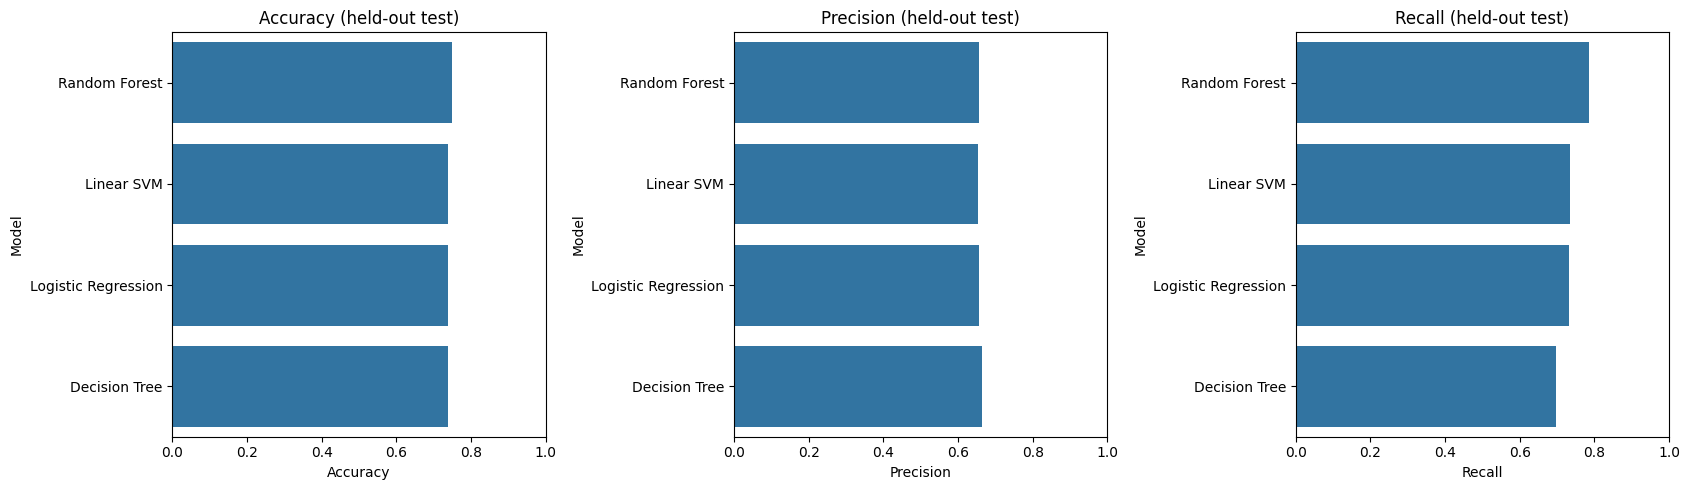

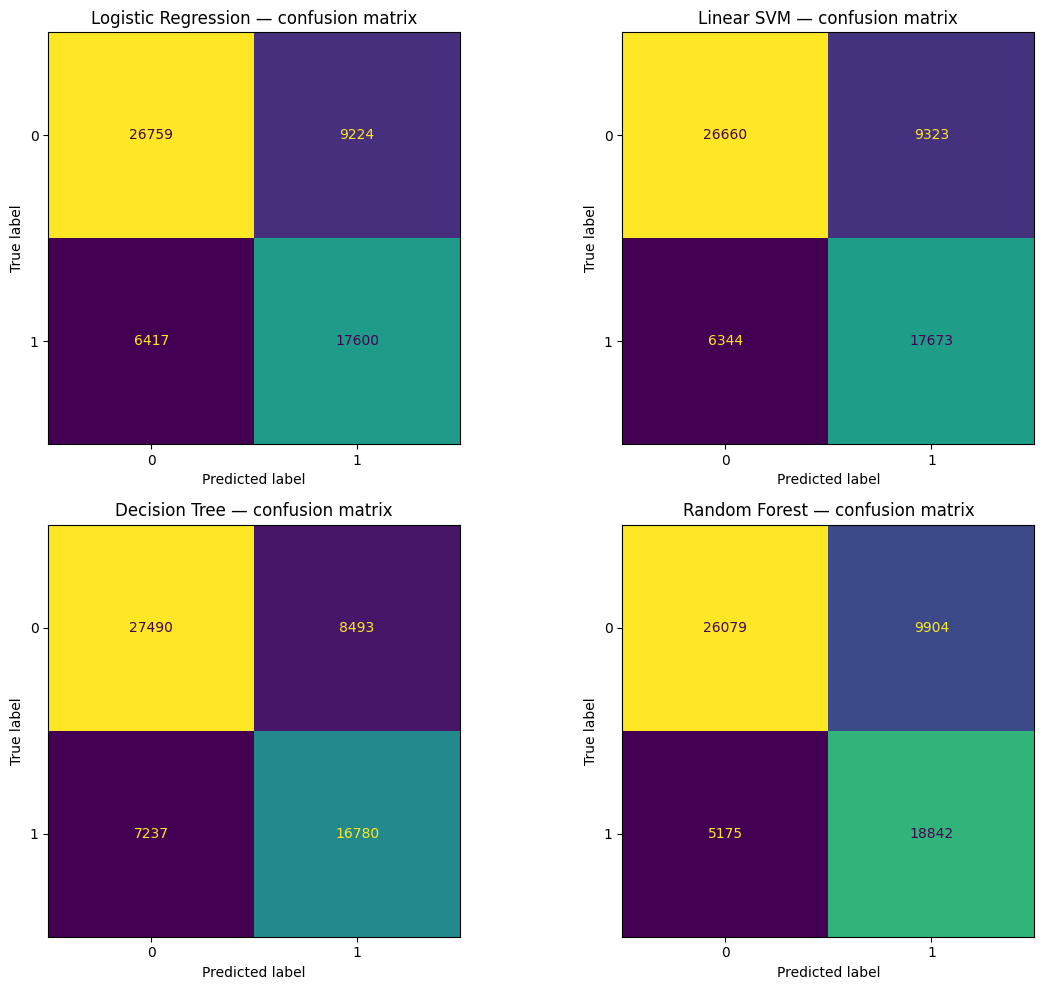

<Figure size 900x700 with 0 Axes>

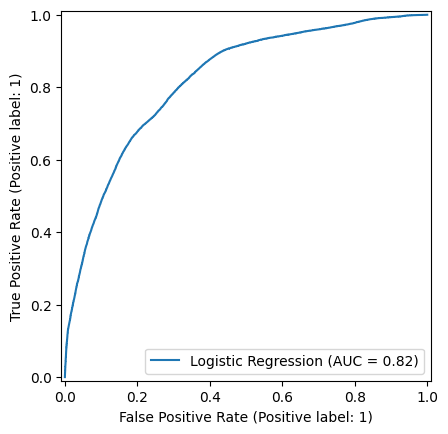

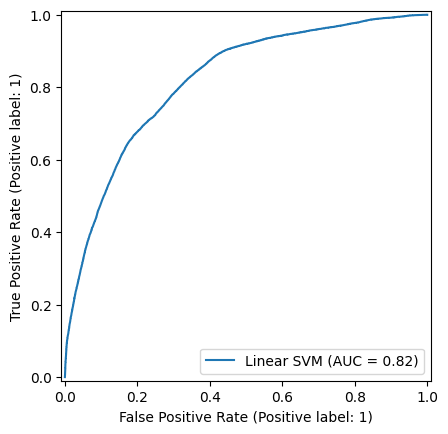

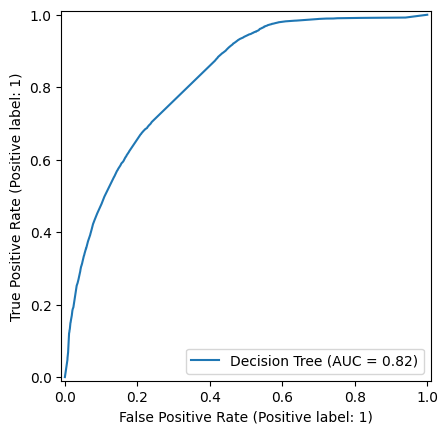

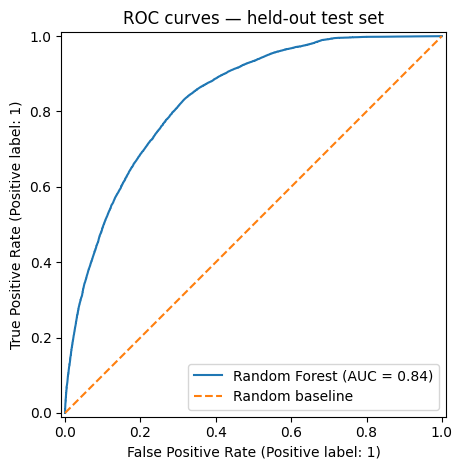

In [45]:
# Compare test metrics
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metric in zip(axes, ["Accuracy", "Precision", "Recall"]):
    sns.barplot(data=results_df, x=metric, y="Model", ax=ax)
    ax.set_xlim(0, 1)
    ax.set_title(f"{metric} (held-out test)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, pred) in zip(axes.flatten(), predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
    ax.set_title(f"{name} — confusion matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
for name, y_score in scores.items():
    if y_score is not None:
        RocCurveDisplay.from_predictions(y_test, y_score, name=name)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.title("ROC curves — held-out test set")
plt.legend()
plt.tight_layout()
plt.show()


### Methodological limitation

Feature selection above uses a validation subset carved from the training partition, then the selected feature list is fixed for cross-validation. This avoids test-set leakage, but it is not fully nested feature selection. For publication-grade estimates, repeat feature selection inside each cross-validation fold (nested CV) and report confidence intervals. Also justify whether `Weapon Desc` and other fields are genuinely available at the intended prediction time, and assess potential bias in victim-related variables.


# MODULE 2 — GEOGRAPHIC CRIME HOTSPOT ANALYSIS

# PART 46 — Geographic Dataset

In [46]:
geo_df = df[
    [
        "LAT",
        "LON",
        "AREA",
        "AREA NAME",
        "Crm Cd Desc",
        "Year",
        "Month",
        "Hour",
        "TimeOfDay",
        "Part 1-2"
    ]
].copy()

geo_df = geo_df.dropna(
    subset=[
        "LAT",
        "LON"
    ]
)

# Check Geographic Range

In [47]:
print(
    geo_df[
        ["LAT", "LON"]
    ].describe()
)

geo_df = geo_df[
    (geo_df["LAT"] != 0) &
    (geo_df["LON"] != 0)
]

                LAT           LON
count  1.005198e+06  1.005198e+06
mean   3.399820e+01 -1.180909e+02
std    1.610549e+00  5.581812e+00
min    0.000000e+00 -1.186676e+02
25%    3.401470e+01 -1.184305e+02
50%    3.405890e+01 -1.183225e+02
75%    3.416490e+01 -1.182739e+02
max    3.433430e+01  0.000000e+00


# Crime Density Map

In [48]:
map_sample = geo_df.sample(
    min(30000, len(geo_df)),
    random_state=42
)
crime_map = folium.Map(
    location=[
        map_sample["LAT"].mean(),
        map_sample["LON"].mean()
    ],
    zoom_start=10
)

# Heatmap

In [49]:
heat_data = map_sample[
    ["LAT", "LON"]
].values.tolist()

HeatMap(
    heat_data,
    radius=10,
    blur=15,
    min_opacity=0.3
).add_to(crime_map)
 
crime_map

# PART 50 — Interactive Crime Map by Area

In [50]:
area_geo = (
    geo_df
    .groupby("AREA NAME")
    .agg(
        Crime_Count=("AREA NAME", "size"),
        Latitude=("LAT", "mean"),
        Longitude=("LON", "mean")
    )
    .reset_index()
)

area_geo = area_geo.sort_values(
    "Crime_Count",
    ascending=False
)

area_geo.head(20)

,AREA NAME,Crime_Count,Latitude,Longitude
1,Central,69480,34.047659,-118.250586
0,77th Street,61630,33.977692,-118.297310
12,Pacific,59347,33.983535,-118.423498
15,Southwest,57446,34.020254,-118.316198
6,Hollywood,52108,34.099366,-118.329648
8,N Hollywood,51015,34.171628,-118.384630
11,Olympic,49941,34.060169,-118.300403
14,Southeast,49800,33.938888,-118.267151
9,Newton,49083,34.009579,-118.260593
20,Wilshire,48109,34.061854,-118.352082


# PART 52 — Crime Type Geographic Analysis

In [51]:
crime_types = (
    geo_df["Crm Cd Desc"]
    .value_counts()
    .head(10)
    .index
)

crime_types

Index(['VEHICLE - STOLEN', 'BATTERY - SIMPLE ASSAULT', 'BURGLARY FROM VEHICLE',
       'THEFT OF IDENTITY',
       'VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)', 'BURGLARY',
       'THEFT PLAIN - PETTY ($950 & UNDER)',
       'ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT',
       'INTIMATE PARTNER - SIMPLE ASSAULT',
       'THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER)'],
      dtype='object', name='Crm Cd Desc')

# MODULE 3 — HISTORICAL CRIME RISK PREDICTION

**Interpretation note**

We should NOT claim: “The model predicts that a crime will definitely happen.” Instead: “The system estimates historical crime risk based on previously observed crime frequency for a given area and time combination.”


# PART 53 — Build area-time historical counts

This version evaluates on the **latest observed year** rather than a random split. The label thresholds are learned from training years only. These are retrospective historical-risk categories, not a guarantee that a crime will occur.


In [52]:
# Prepare annual area-time counts for chronological evaluation.

required_risk_cols = ["DATE OCC", "AREA NAME", "Hour", "DayOfWeek"]
missing_risk = [c for c in required_risk_cols if c not in df.columns]
if missing_risk:
    raise KeyError(f"Required columns missing from df: {missing_risk}")

risk_base = df[required_risk_cols].copy()
risk_base["DATE OCC"] = pd.to_datetime(risk_base["DATE OCC"], errors="coerce")
risk_base["Year"] = risk_base["DATE OCC"].dt.year
for col in ["Year", "Hour", "DayOfWeek"]:
    risk_base[col] = pd.to_numeric(risk_base[col], errors="coerce")
risk_base = risk_base.dropna(
    subset=["DATE OCC", "AREA NAME", "Year", "Hour", "DayOfWeek"]
).copy()
for col in ["Year", "Hour", "DayOfWeek"]:
    risk_base[col] = risk_base[col].astype(int)

# Each row is the historical count for one area × year × hour × weekday.
risk_frequency = (
    risk_base.groupby(["AREA NAME", "Year", "Hour", "DayOfWeek"], observed=True)
    .size()
    .reset_index(name="Crime_Count")
)
print("Area-time-year groups:", len(risk_frequency))
print("Years available:", sorted(risk_frequency["Year"].unique()))
display(risk_frequency.head())


Area-time-year groups: 17728
Years available: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,AREA NAME,Year,Hour,DayOfWeek,Crime_Count
0,77th Street,2020,0,0,36
1,77th Street,2020,0,1,30
2,77th Street,2020,0,2,51
3,77th Street,2020,0,3,31
4,77th Street,2020,0,4,30


In [53]:
# PART 54 — Chronological split and training-only risk thresholds

year_values = sorted(risk_frequency["Year"].unique())
if len(year_values) < 2:
    raise ValueError("At least two distinct years are required for chronological evaluation.")

# The latest dataset year may be incomplete. Use it only if December is present;
# otherwise evaluate on the preceding complete year.
latest_year = year_values[-1]
latest_month = int(risk_base.loc[risk_base["Year"] == latest_year, "DATE OCC"].dt.month.max())
test_year = latest_year if latest_month == 12 else year_values[-2]
risk_train = risk_frequency[risk_frequency["Year"] < test_year].copy()
risk_test = risk_frequency[risk_frequency["Year"] == test_year].copy()
if risk_train.empty or risk_test.empty:
    raise ValueError("Chronological split produced an empty train or test set.")

q1 = risk_train["Crime_Count"].quantile(0.33)
q2 = risk_train["Crime_Count"].quantile(0.66)

def assign_risk(count, low=q1, high=q2):
    if count <= low:
        return "LOW"
    if count <= high:
        return "MEDIUM"
    return "HIGH"

risk_train["Risk"] = risk_train["Crime_Count"].apply(assign_risk)
risk_test["Risk"] = risk_test["Crime_Count"].apply(assign_risk)
risk_labels = ["LOW", "MEDIUM", "HIGH"]
print(f"Training years: {min(risk_train['Year'])}–{max(risk_train['Year'])}")
print(f"Held-out complete test year: {test_year}")
print(f"Training-derived thresholds: LOW <= {q1:.2f}; MEDIUM <= {q2:.2f}; HIGH > {q2:.2f}")
print("Training labels:\n", risk_train["Risk"].value_counts())
print("Test labels:\n", risk_test["Risk"].value_counts())


Training years: 2020–2023
Held-out complete test year: 2024
Training-derived thresholds: LOW <= 19.00; MEDIUM <= 30.00; HIGH > 30.00
Training labels:
 Risk
MEDIUM    4913
LOW       4784
HIGH      4414
Name: count, dtype: int64
Test labels:
 Risk
LOW       2588
MEDIUM     796
HIGH       144
Name: count, dtype: int64


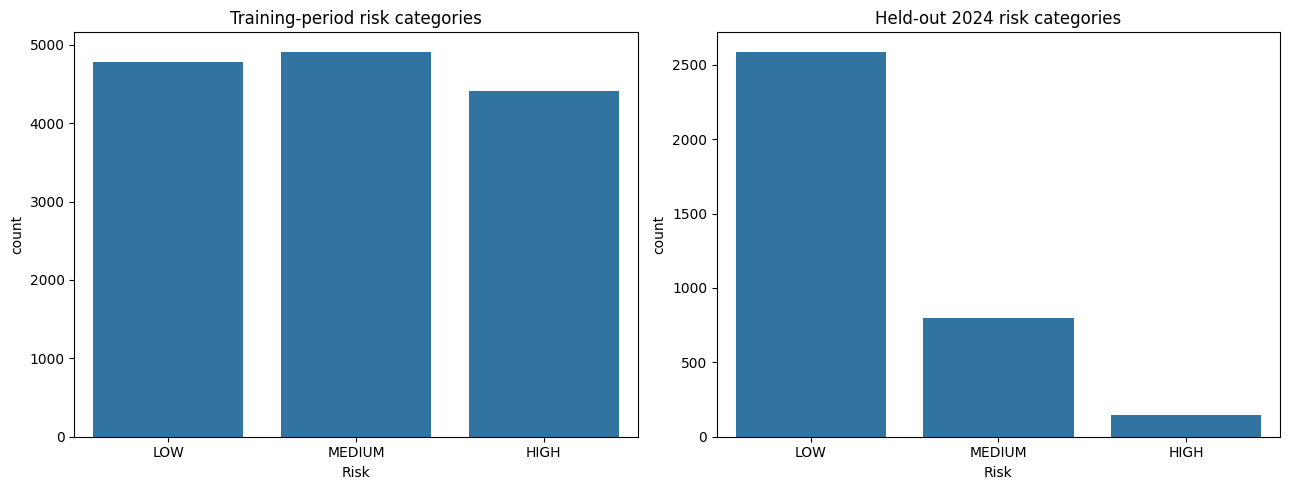

Risk,HIGH,LOW,MEDIUM,Total Groups
AREA NAME,,,,
77th Street,431,203,206,840
Central,462,157,221,840
Devonshire,128,433,279,840
Foothill,45,559,236,840
Harbor,123,401,316,840
Hollenbeck,63,478,299,840
Hollywood,262,300,278,840
Mission,101,415,324,840
N Hollywood,250,292,298,840


In [54]:
# PART 55 — Visualize historical risk distribution (descriptive only)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=risk_train, x="Risk", order=risk_labels, ax=axes[0])
axes[0].set_title("Training-period risk categories")
sns.countplot(data=risk_test, x="Risk", order=risk_labels, ax=axes[1])
axes[1].set_title(f"Held-out {test_year} risk categories")
plt.tight_layout()
plt.show()

risk_labeled = pd.concat([risk_train, risk_test], ignore_index=True)
risk_area = pd.crosstab(risk_labeled["AREA NAME"], risk_labeled["Risk"])
for label in risk_labels:
    if label not in risk_area.columns:
        risk_area[label] = 0
risk_area["Total Groups"] = risk_area[risk_labels].sum(axis=1)
risk_area = risk_area.sort_values("Total Groups", ascending=False)
display(risk_area.head(15))


In [55]:
# PART 56 — Train on earlier years and evaluate on the held-out complete year

# These inputs match the existing Streamlit risk form. Year is used to create a
# chronological evaluation split, but not required from an app user at prediction time.
risk_features = ["AREA NAME", "Hour", "DayOfWeek"]
risk_numeric = ["Hour", "DayOfWeek"]
risk_categorical = ["AREA NAME"]
X_risk_train = risk_train[risk_features].copy()
y_risk_train = risk_train["Risk"].copy()
X_risk_test = risk_test[risk_features].copy()
y_risk_test = risk_test["Risk"].copy()

risk_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), risk_numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), risk_categorical)
], remainder="drop")
risk_model = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, class_weight="balanced",
    n_jobs=-1, random_state=42
)
risk_pipeline = Pipeline([("preprocessor", risk_preprocessor), ("model", risk_model)])
risk_pipeline.fit(X_risk_train, y_risk_train)
risk_pred = risk_pipeline.predict(X_risk_test)
print(classification_report(y_risk_test, risk_pred, labels=risk_labels, zero_division=0))
print("Held-out-year accuracy:", round(accuracy_score(y_risk_test, risk_pred), 4))
print("Confusion matrix (LOW, MEDIUM, HIGH):\n", confusion_matrix(
    y_risk_test, risk_pred, labels=risk_labels
))


              precision    recall  f1-score   support

         LOW       0.98      0.44      0.61      2588
      MEDIUM       0.19      0.29      0.23       796
        HIGH       0.11      0.89      0.20       144

    accuracy                           0.43      3528
   macro avg       0.43      0.54      0.35      3528
weighted avg       0.77      0.43      0.51      3528

Held-out-year accuracy: 0.4266
Confusion matrix (LOW, MEDIUM, HIGH):
 [[1148  957  483]
 [  14  229  553]
 [   4   12  128]]


In [56]:
# PART 57 — Save the app-compatible risk pipeline and separate metadata

joblib.dump(risk_pipeline, "crime_risk_model.pkl")
risk_metadata = {
    "risk_features": risk_features,
    "risk_threshold_low": float(q1),
    "risk_threshold_high": float(q2),
    "test_year": int(test_year),
    "risk_labels": risk_labels,
    "description": "Retrospective area-time risk category model; not a deterministic crime prediction."
}
joblib.dump(risk_metadata, "crime_risk_model_metadata.pkl")
print("Saved crime_risk_model.pkl and crime_risk_model_metadata.pkl")


Saved crime_risk_model.pkl and crime_risk_model_metadata.pkl


In [57]:
# PART 58 — Example historical-risk estimate

sample_risk = pd.DataFrame({
    "AREA NAME": ["Central"],
    "Hour": [23],
    "DayOfWeek": [5]
})
predicted_risk = risk_pipeline.predict(sample_risk)[0]
print("Estimated historical risk category:", predicted_risk)
print("Interpretation: this is learned from historical area-time counts, not a guarantee that a crime will occur.")

risk_probability = risk_pipeline.predict_proba(sample_risk)[0]
risk_classes = risk_pipeline.named_steps["model"].classes_
risk_result = pd.DataFrame({"Risk": risk_classes, "Probability": risk_probability})
display(risk_result.sort_values("Probability", ascending=False).reset_index(drop=True))


Estimated historical risk category: HIGH
Interpretation: this is learned from historical area-time counts, not a guarantee that a crime will occur.


,Risk,Probability
0,HIGH,0.830672
1,MEDIUM,0.163786
2,LOW,0.005542


### Limitations of the risk module

This is a chronological baseline, but it still does not model lagged crime counts, population/exposure, changes in reporting practices, or uncertainty. The aggregated count rows are not independent events, and risk labels are relative to thresholds learned from earlier years. Avoid interpreting the outputs as causal, individual-level, or guaranteed predictions.


In [58]:
crime_mapping = (
    df[['Crm Cd', 'Crm Cd Desc', 'Part 1-2']]
    .drop_duplicates()
    .sort_values(['Part 1-2', 'Crm Cd'])
)

crime_mapping

,Crm Cd,Crm Cd Desc,Part 1-2
1863,110,CRIMINAL HOMICIDE,1
10338,113,"MANSLAUGHTER, NEGLIGENT",1
72,121,"RAPE, FORCIBLE",1
1425,122,"RAPE, ATTEMPTED",1
46,210,ROBBERY,1
...,...,...,...
8996,949,ILLEGAL DUMPING,2
4402,950,"DEFRAUDING INNKEEPER/THEFT OF SERVICES, OVER $...",2
631,951,"DEFRAUDING INNKEEPER/THEFT OF SERVICES, $950 &...",2
32520,954,CONTRIBUTING,2
